<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME_640_10_RBDO_Data_Informed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ME 640 — Reliability-Based Design Optimization
## Data-Informed and Surrogate-Assisted RBDO
### UCI Concrete Compressive Strength case study

### Objectives
Build and validate a data-driven performance surrogate; define a data-informed limit state; propagate manufacturing uncertainty; estimate reliability; map a reliable design region; and distinguish input uncertainty from surrogate/model uncertainty.

The final numerical mixtures are instructional, not production recommendations.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import minimize
np.random.seed(640)
plt.rcParams["figure.figsize"]=(7,5)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score
def load_data():
 url="https://archive.ics.uci.edu/ml/machine-learning-databases/concrete/compressive/Concrete_Data.xls"
 try:
  d=pd.read_excel(url); d.columns=["Cement","Slag","FlyAsh","Water","Superplasticizer","CoarseAggregate","FineAggregate","Age","Strength"]
  print("Loaded public UCI data."); return d
 except Exception:
  print("Online file unavailable: deterministic teaching fallback.")
  r=np.random.default_rng(640);n=1030
  d=pd.DataFrame({"Cement":r.uniform(100,540,n),"Slag":r.uniform(0,300,n),"FlyAsh":r.uniform(0,190,n),"Water":r.uniform(120,245,n),"Superplasticizer":r.uniform(0,30,n),"CoarseAggregate":r.uniform(800,1150,n),"FineAggregate":r.uniform(590,990,n),"Age":r.choice([7,14,28,56,90,180,365],n)})
  wc=d.Water/(d.Cement+.3*d.Slag+1e-9);d["Strength"]=15+.075*d.Cement+.025*d.Slag+.16*d.Superplasticizer-22*wc+7*np.log1p(d.Age)/np.log(366)+r.normal(0,4,n)
  return d
data=load_data();display(data.head());display(data.describe().T.round(2))

Loaded public UCI data.


,Cement,Slag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
Slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
FlyAsh,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
Water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
Superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
CoarseAggregate,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
FineAggregate,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
Age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
Strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


# 1. Data-informed limit states
If a validated surrogate predicts performance,
$
\hat y=\hat f(\mathbf x),
$
and the requirement is $y\ge y_{\min}$, define
$
g(\mathbf x)=\hat f(\mathbf x)-y_{\min}.
$
Reliability analysis then propagates uncertain inputs through $\hat f$.

Crucial distinction:
$$
\boxed{\text{physical/input uncertainty}\neq\text{surrogate/model error}}.
$$
A reliable-looking probability computed from an inaccurate surrogate is not trustworthy.

# 2. Fit and validate a nonlinear surrogate
The UCI dataset contains 1,030 observations, eight quantitative inputs, and compressive strength as the target. We use a Random Forest for a convenient nonlinear demonstration; it is not assumed uniquely optimal.

RMSE = 5.417942061272237  R2 = 0.8984064225052856


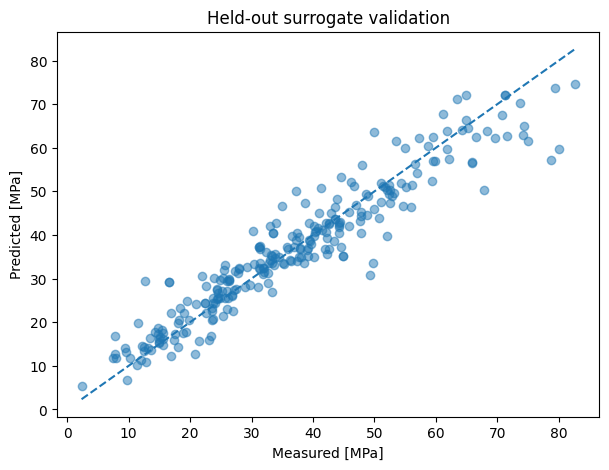

In [ ]:
features=["Cement","Slag","FlyAsh","Water","Superplasticizer","CoarseAggregate","FineAggregate","Age"]
X=data[features];y=data.Strength
Xt,Xv,yt,yv=train_test_split(X,y,test_size=.25,random_state=640)
rf=RandomForestRegressor(n_estimators=400,min_samples_leaf=2,random_state=640,n_jobs=-1).fit(Xt,yt)
p=rf.predict(Xv);print("RMSE =",mean_squared_error(yv,p)**.5," R2 =",r2_score(yv,p))
fig,ax=plt.subplots();ax.scatter(yv,p,alpha=.5);lo=min(yv.min(),p.min());hi=max(yv.max(),p.max());ax.plot([lo,hi],[lo,hi],"--")
ax.set(xlabel="Measured [MPa]",ylabel="Predicted [MPa]",title="Held-out surrogate validation");plt.show()

# 3. Reliability requirement and uncertainty model
For illustration require
$$
f_c\ge40\text{ MPa},\qquad g=\hat f_c-40.
$$
We optimize nominal cement and water while fixing other inputs at representative values. Manufacturing variation is introduced as a **teaching assumption**:
$$
C\sim\mathcal N(d_C,(0.03d_C)^2),\qquad
W\sim\mathcal N(d_W,(0.02d_W)^2).
$$
These uncertainty statistics are not supplied by UCI.

In [ ]:
fixed={k:float(data[k].median()) for k in ["Slag","FlyAsh","Superplasticizer","CoarseAggregate","FineAggregate"]};fixed["Age"]=28.
def samples(c,w,N=3000,seed=1):
 r=np.random.default_rng(seed)
 df=pd.DataFrame({"Cement":r.normal(c,.03*c,N),"Slag":fixed["Slag"],"FlyAsh":fixed["FlyAsh"],"Water":r.normal(w,.02*w,N),"Superplasticizer":fixed["Superplasticizer"],"CoarseAggregate":fixed["CoarseAggregate"],"FineAggregate":fixed["FineAggregate"],"Age":28.})
 return rf.predict(df[features])
def stats(c,w,N=3000):
 yy=samples(c,w,N);g=yy-40;pf=np.mean(g<0);pc=max(pf,.5/N)
 return yy.mean(),yy.std(ddof=1),pf,-norm.ppf(pc)

Monte Carlo estimates
$$
\hat P_f=\frac1N\sum I[g^{(k)}<0],\qquad
\beta_{MC}=-\Phi^{-1}(\hat P_f).
$$
Response distributions make clear why nominal performance alone is insufficient.

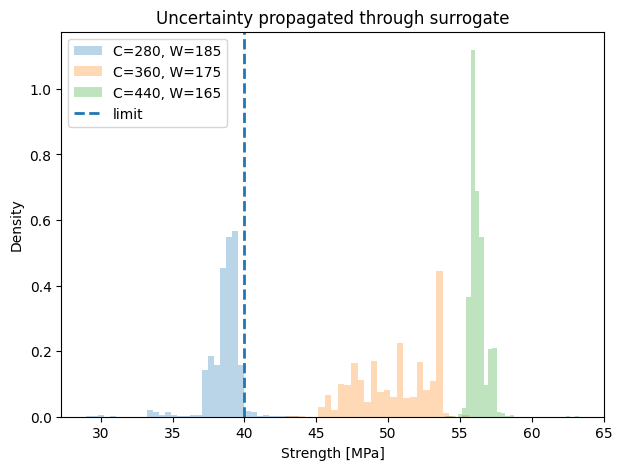

In [ ]:
fig,ax=plt.subplots()
for i,(c,w) in enumerate([(280,185),(360,175),(440,165)]):
 yy=samples(c,w,5000,20+i);ax.hist(yy,bins=35,density=True,alpha=.3,label=f"C={c}, W={w}")
ax.axvline(40,ls="--",lw=2,label="limit");ax.set(xlabel="Strength [MPa]",ylabel="Density",title="Uncertainty propagated through surrogate");ax.legend();plt.show()

# 4. Reliable design map
For many candidate nominal designs:
$$
\mathbf d\rightarrow\text{uncertain realizations}\rightarrow\hat f
\rightarrow P_f,\beta.
$$
For illustration, lower cement content is preferred subject to $\beta\ge2$.

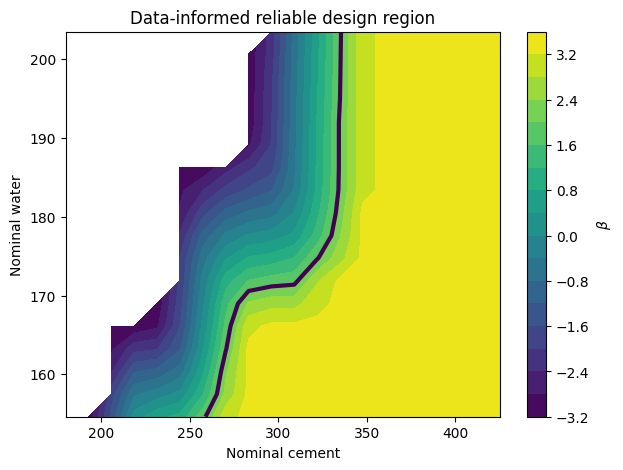

In [ ]:
cs=np.linspace(max(180,data.Cement.quantile(.1)),min(500,data.Cement.quantile(.9)),20)
ws=np.linspace(max(135,data.Water.quantile(.1)),min(215,data.Water.quantile(.9)),18)
rows=[]
for c in cs:
 for w in ws:
  mu,sd,pf,b=stats(c,w,1000);rows.append([c,w,mu,sd,pf,b])
gr=pd.DataFrame(rows,columns=["Cement","Water","Mean","SD","Pf","Beta"])
pv=gr.pivot(index="Water",columns="Cement",values="Beta")
fig,ax=plt.subplots();cf=ax.contourf(pv.columns,pv.index,pv.values,levels=20);plt.colorbar(cf,ax=ax,label=r"$\beta$")
ax.contour(pv.columns,pv.index,pv.values,levels=[2],linewidths=3)
ax.set(xlabel="Nominal cement",ylabel="Nominal water",title="Data-informed reliable design region");plt.show()

# 5. Moment reliability versus simulation
If the surrogate margin were approximately Gaussian,
$
\beta_{\text{moment}}\approx\frac{\mu_g}{\sigma_g}.
$
But nonlinear/tree-based predictions need not be Gaussian. Compare this approximation with the Monte-Carlo-equivalent $\beta$.

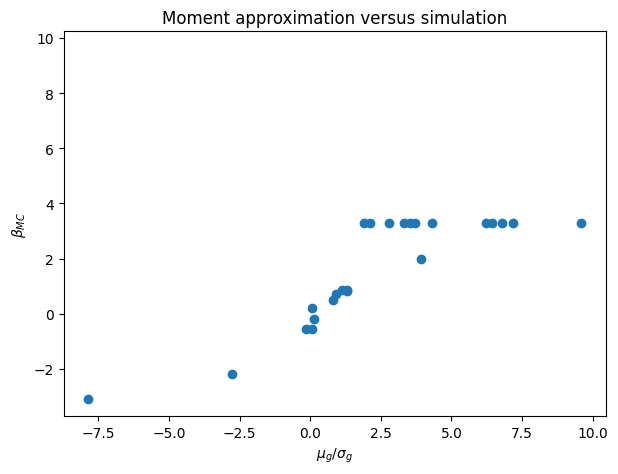

In [ ]:
s=gr.sample(35,random_state=640).copy();s["BM"]=(s.Mean-40)/s.SD
fig,ax=plt.subplots();ax.scatter(s.BM,s.Beta);lo=min(s.BM.min(),s.Beta.min());hi=max(s.BM.max(),s.Beta.max());ax.plot([lo,hi],[lo,hi],"--")
ax.set(xlabel=r"$\mu_g/\sigma_g$",ylabel=r"$\beta_{MC}$",title="Moment approximation versus simulation");plt.show()

# 6. Surrogate-assisted RBDO risks
Global $R^2$ alone is insufficient. RBDO particularly needs accuracy near $g=0$, because small model errors there can change safe/failure classification.

Safeguards:
- held-out and local validation;
- domain/familiarity checks;
- uncertainty-aware surrogates;
- adaptive sampling near the limit state;
- high-fidelity verification of the final design.

$$
\boxed{\text{Data}\to\text{surrogate}\to\text{limit state}\to\text{uncertainty propagation}\to\text{reliability}\to\text{optimization}\to\text{verification}}
$$
